# Notebook 6 — **3D crosswind** (deterministic forward PINN)
### Wind-relative drag · elevation *and* azimuth · an *inferred* impact time

**Where I am in the project.** Notebooks 1–5 lived in a flat, deterministic world: a 2-D
plane, a single launch angle, and — at worst — a steady drag coefficient. This notebook steps
up into three dimensions with a crosswind. Two things change, and each is a genuine physics /
maths step up, not just more code:

1. **3-D crosswind.** Drag no longer opposes my ground velocity — it opposes my velocity
   *relative to the moving air*. A sideways wind therefore bleeds sideways momentum in and
   pushes the projectile off-line. I need a third spatial axis and two launch angles
   (**elevation** *and* **azimuth**).
2. **An *inferred* impact time.** In Notebook 3 I looked flight time up from a precomputed
   RK4 table. In 3-D-with-wind that table would need 5 axes — hopeless. So I make the impact
   time a *learned output* of a small second network, trained by the landing condition itself.

**My roadmap for this notebook.** 3-D wind-relative physics → RK4 ground truth → a forward
PINN that generalises over $(\theta,\phi,k,\mathbf w)$ **and infers its own impact time** →
validate against RK4 → a small sensitivity map over azimuth and crosswind. Everything here is
**deterministic**: one set of inputs gives exactly one trajectory.

## Setup
Same tools as before: PyTorch for the network + autograd, NumPy for the numerical ground
truth (RK4), and Matplotlib for plots. Seeds fixed so every number here is reproducible.


In [79]:
# ── Imports ───────────────────────────────────────────────────────────────────
# torch      : neural network + automatic differentiation (our physics residuals)
# torch.nn   : ready-made layers (Linear, Tanh) and the Module base class
# numpy      : the CPU "ground truth" integrator (RK4)
# matplotlib : all plots, including the 3-D trajectory view
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D          # noqa: enables 3-D plotting

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# Reproducibility: same seed -> same random collocation points every run.
torch.manual_seed(0)
np.random.seed(0)

Device: cuda


## The physics, written out carefully
**My coordinates.** I keep $y$ pointing **up** (so gravity is $-g\,\hat{\mathbf y}$, exactly as
in every earlier notebook) and add a third horizontal axis:
- $x$ = **downrange** (the direction I am nominally aiming),
- $y$ = **vertical** (up),
- $z$ = **crossrange** (horizontal, at right angles to $x$ — the way a crosswind blows).

**Two launch angles now.** In 2-D one angle (elevation $\theta$) was enough. In 3-D I also
need an **azimuth** $\phi$ — the compass heading in the horizontal plane. With launch speed
$u$:
$$ v_x(0)=u\cos\theta\cos\phi,\qquad v_y(0)=u\sin\theta,\qquad v_z(0)=u\cos\theta\sin\phi. $$
Sanity: the horizontal speed is $u\cos\theta$, split between downrange and crossrange by the
azimuth; $\phi=0$ recovers my old 2-D launch exactly.

**The one idea that changes everything: wind-relative drag.** A projectile does not "feel" the
ground — it feels the *air rushing past it*. If the air itself moves with wind velocity
$\mathbf w=(w_x,w_y,w_z)$, then what drives drag is the **air-relative velocity**
$$ \mathbf v_{\text{rel}}=\mathbf v-\mathbf w. $$
Quadratic drag opposes *that* vector with magnitude $\propto|\mathbf v_{\text{rel}}|^2$, so
Newton's second law (per unit mass, with $k=b/m$) becomes
$$ \dot{\mathbf v}= -g\,\hat{\mathbf y}\;-\;k\,\lvert\mathbf v-\mathbf w\rvert\,(\mathbf v-\mathbf w). $$
Writing it out per component with a **horizontal** wind $\mathbf w=(w_x,0,w_z)$ and
$v_{\text{rel}}=\sqrt{(v_x-w_x)^2+v_y^2+(v_z-w_z)^2}$:
$$ \dot v_x=-k\,v_{\text{rel}}\,(v_x-w_x),\quad
   \dot v_y=-g-k\,v_{\text{rel}}\,v_y,\quad
   \dot v_z=-k\,v_{\text{rel}}\,(v_z-w_z). $$

**Why this is the physically correct move (and a common trap).** It is tempting to just add a
sideways force, but that is wrong: drag is *nonlinear* in the air-relative speed, so a
crosswind does not only push sideways — by changing $v_{\text{rel}}$ it also subtly changes the
downrange and vertical drag. Using $\mathbf v-\mathbf w$ inside the *magnitude* is what captures
that coupling. Set $\mathbf w=\mathbf 0$ and $\phi=0$ and every equation collapses back to
Notebook 3 — so this notebook strictly *contains* the old one.

In [80]:
# ── Physical constants and the ranges we will generalise over ──────────────────
g = 9.81                       # gravity (m/s^2), acts along -y

u_fixed = 30.0                 # launch SPEED fixed at 30 m/s (as in Notebook 3);
                               # we generalise over the two ANGLES, drag, and WIND.

# The PINN will learn EVERY combination inside these boxes:
theta_min, theta_max = 30.0, 60.0     # elevation (deg above horizontal)
phi_min,   phi_max   = -15.0, 15.0    # azimuth   (deg left/right of downrange); 0 = straight
k_min,     k_max     = 0.0,  0.02     # drag-per-unit-mass (1/m); 0 = vacuum
w_min,     w_max     = -8.0, 8.0      # horizontal wind component (m/s) on each of x,z

print(f"Launch speed (fixed) : {u_fixed} m/s")
print(f"Elevation theta      : {theta_min}-{theta_max} deg")
print(f"Azimuth   phi        : {phi_min}-{phi_max} deg")
print(f"Drag      k          : {k_min}-{k_max} 1/m")
print(f"Wind (wx, wz) each   : {w_min}-{w_max} m/s")

Launch speed (fixed) : 30.0 m/s
Elevation theta      : 30.0-60.0 deg
Azimuth   phi        : -15.0-15.0 deg
Drag      k          : 0.0-0.02 1/m
Wind (wx, wz) each   : -8.0-8.0 m/s


## All the physics in one function
As in Notebook 3 I pack the whole state into a vector and write a single `deriv3d(s)` that
returns $\dot s$. This one function *is* the physics; the RK4 integrator below just calls it
repeatedly. The state is now 6-dimensional, $s=[x,y,z,v_x,v_y,v_z]$, and the wind enters only
through the air-relative velocity.

In [81]:
# ── Right-hand side of the 3-D ODE system: ds/dt = deriv3d(s) ─────────────────
# State s = [x, y, z, vx, vy, vz]. Wind is a 3-vector (we use horizontal winds).
# The ONLY new idea vs Notebook 3 is (vx-wx, vy-wy, vz-wz): the AIR-relative velocity.
def deriv3d(s, k, wind):
    x, y, z, vx, vy, vz = s
    wx, wy, wz = wind
    vrx, vry, vrz = vx - wx, vy - wy, vz - wz          # air-relative velocity components
    vrel = np.sqrt(vrx*vrx + vry*vry + vrz*vrz)         # air-relative SPEED (drives drag)
    ax = -k * vrel * vrx                                 # drag only (no gravity sideways)
    ay = -g - k * vrel * vry                             # gravity + drag
    az = -k * vrel * vrz                                 # drag only
    return np.array([vx, vy, vz, ax, ay, az])           # = ds/dt

## RK4 in 3-D, and detecting the landing
Nothing about Runge–Kutta 4 changes when the state grows from 4 to 6 numbers — RK4 samples the
slope four times per step and takes a weighted average, and it does that componentwise. I march
until $y$ crosses zero (the projectile lands) and linearly interpolate the exact landing state,
which gives me a clean impact point $(x,z)$ and impact time. This RK4 solution is my **trusted
ground truth** for the whole deterministic part.

In [82]:
# ── One RK4 step (identical structure to Notebook 3, just a 6-vector state) ────
def rk4_step3d(s, dt, k, wind):
    k1 = deriv3d(s,             k, wind)
    k2 = deriv3d(s + dt/2 * k1, k, wind)
    k3 = deriv3d(s + dt/2 * k2, k, wind)
    k4 = deriv3d(s + dt   * k3, k, wind)
    return s + dt/6 * (k1 + 2*k2 + 2*k3 + k4)

# ── Integrate from launch until landing (y returns to 0) ──────────────────────
def integrate3d(u, theta_deg, phi_deg, k, wind, dt=0.002, t_max=20.0):
    th, ph = np.radians(theta_deg), np.radians(phi_deg)
    # initial velocity split by BOTH angles (see the physics markdown)
    vx0 = u*np.cos(th)*np.cos(ph)
    vy0 = u*np.sin(th)
    vz0 = u*np.cos(th)*np.sin(ph)
    s = np.array([0.0, 0.0, 0.0, vx0, vy0, vz0])
    T=[0.0]; S=[s.copy()]; t=0.0
    while t < t_max:
        sn = rk4_step3d(s, dt, k, wind)
        if sn[1] < 0 and s[1] >= 0:                      # y crossed zero -> landed
            frac = s[1] / (s[1] - sn[1])                 # fraction of step to reach y=0
            s_land = s + frac * (sn - s)                 # interpolate the landing state
            t += frac*dt; T.append(t); S.append(s_land); break
        s = sn; t += dt; T.append(t); S.append(s.copy())
    S = np.array(S)
    return np.array(T), S      # S columns: x,y,z,vx,vy,vz

# ── Two smoke tests ───────────────────────────────────────────────────────────
# (1) No wind, phi=0 -> must reduce to the 2-D Notebook-3 flight (z stays 0).
T,S = integrate3d(u_fixed, 45, 0, 0.01, (0,0,0))
print(f"no wind, phi=0 : range={S[-1,0]:.2f} m  peak={S[:,1].max():.2f} m  "
      f"max|z|={np.abs(S[:,2]).max():.1e} m  (should be ~0)  Tf={T[-1]:.3f} s")
# (2) An 8 m/s crosswind in +z should blow the impact sideways.
T,S = integrate3d(u_fixed, 45, 0, 0.01, (0,0,8.0))
print(f"crosswind wz=8: range={S[-1,0]:.2f} m  crossrange z at impact={S[-1,2]:.2f} m")

no wind, phi=0 : range=55.78 m  peak=17.11 m  max|z|=0.0e+00 m  (should be ~0)  Tf=3.723 s
crosswind wz=8: range=54.82 m  crossrange z at impact=8.96 m


## Looking at what a crosswind actually does
Before I model anything, I want to *see* the effect. Three quick views:
1. **Side view** ($x$ vs $y$): a crosswind barely changes the height profile — the sideways
   physics is nearly decoupled from the vertical, so this looks almost like Notebook 3.
2. **Top-down view** ($x$ vs $z$): this is where the story is. With no wind the ground track
   is a straight line; a crosswind bends it sideways, and the drift *grows* with flight time.
3. **Azimuth**: aiming off-axis ($\phi\neq0$) sends it sideways even with no wind — a useful
   contrast, because later I want the inverse problem to tell *aiming error* apart from *wind*.

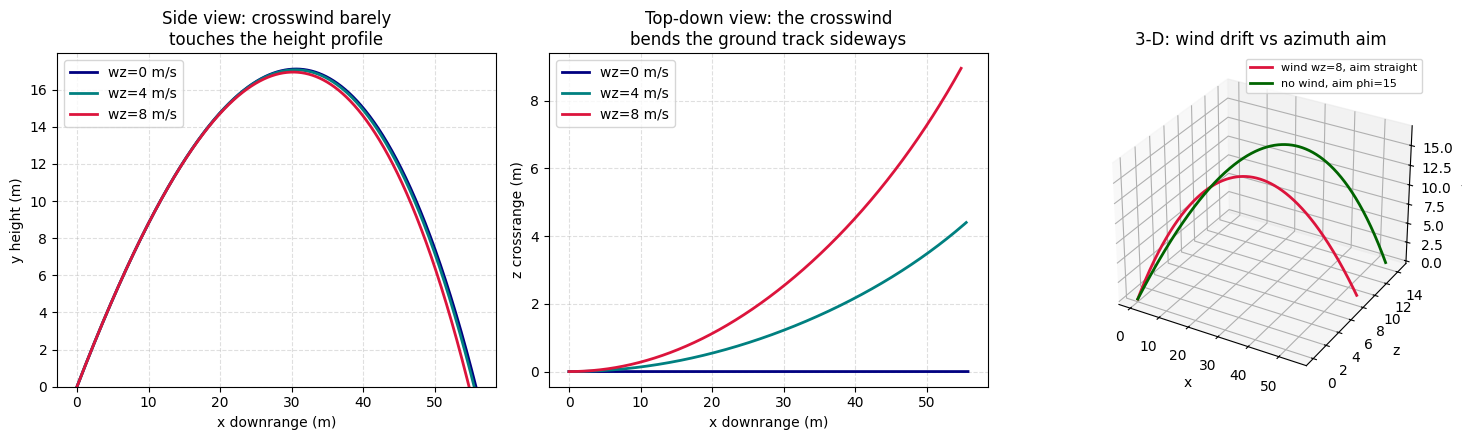

In [83]:
# ── Three views of the crosswind effect ───────────────────────────────────────
fig = plt.figure(figsize=(15,4.5))

# (1) side view: height vs downrange, a few crosswinds
ax1 = fig.add_subplot(1,3,1)
for wz, col in [(0,'navy'), (4,'teal'), (8,'crimson')]:
    _,S = integrate3d(u_fixed, 45, 0, 0.01, (0,0,wz))
    ax1.plot(S[:,0], S[:,1], color=col, lw=2, label=f'wz={wz} m/s')
ax1.set_xlabel('x downrange (m)'); ax1.set_ylabel('y height (m)')
ax1.set_title('Side view: crosswind barely\ntouches the height profile')
ax1.legend(); ax1.grid(True, ls='--', alpha=0.4); ax1.set_ylim(bottom=0)

# (2) top-down: crossrange drift grows with range
ax2 = fig.add_subplot(1,3,2)
for wz, col in [(0,'navy'), (4,'teal'), (8,'crimson')]:
    _,S = integrate3d(u_fixed, 45, 0, 0.01, (0,0,wz))
    ax2.plot(S[:,0], S[:,2], color=col, lw=2, label=f'wz={wz} m/s')
ax2.set_xlabel('x downrange (m)'); ax2.set_ylabel('z crossrange (m)')
ax2.set_title('Top-down view: the crosswind\nbends the ground track sideways')
ax2.legend(); ax2.grid(True, ls='--', alpha=0.4)

# (3) 3-D view: wind drift vs azimuth aim
ax3 = fig.add_subplot(1,3,3, projection='3d')
_,Sa = integrate3d(u_fixed, 45, 0, 0.01, (0,0,8))      # pushed by wind
_,Sb = integrate3d(u_fixed, 45, 15, 0.01, (0,0,0))     # aimed off by azimuth
ax3.plot(Sa[:,0], Sa[:,2], Sa[:,1], color='crimson', lw=2, label='wind wz=8, aim straight')
ax3.plot(Sb[:,0], Sb[:,2], Sb[:,1], color='darkgreen', lw=2, label='no wind, aim phi=15')
ax3.set_xlabel('x'); ax3.set_ylabel('z'); ax3.set_zlabel('y')
ax3.set_title('3-D: wind drift vs azimuth aim'); ax3.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Notice in the top-down view: crossrange drift is small early and grows late in the flight.
# That "grows with time" signature is exactly how an inverse model can later tell wind from aim.

## My forward PINN for the 3-D crosswind problem
**Inputs and outputs.** I keep the *time-domain* idea from Notebook 3 but generalise the family:
$$ (\;\xi,\ \theta,\ \phi,\ k,\ w_x,\ w_z\;)\ \longmapsto\ (\,x,\ y,\ z\,). $$
Here $\xi\in[0,1]$ is a **normalised flight fraction** (like the $\xi$ I used for hard
constraints in Notebooks 1–2): $\xi=0$ is launch, $\xi=1$ is impact. Physical time is
$t=\xi\,T_f$ for that flight's duration $T_f$.

**The new trick: I *infer* the impact time.** In Notebook 3, $T_f$ came from a precomputed RK4
lookup table over $(\theta,k)$. In 3-D-with-wind that table would need five axes and be far too
expensive — the curse of dimensionality. So instead I train a **second, small network**
$$ T_\psi(\theta,\phi,k,w_x,w_z)\ \longmapsto\ T_f>0 $$
jointly with the trajectory network. Nothing tells it the answer directly; it is forced to the
right value by the **landing condition** $y(\xi{=}1)=0$ together with the physics. This is what
my prof means by *"infer impact time"*, and it removes the lookup table entirely (which also
settles the honesty worry I had about the table in Notebook 3).

**Hard constraint — but only at one end this time.** In Notebooks 1–2 I wrote
$y=\xi(1-\xi)N(\xi)$ to *bake in* both $y(0)=0$ **and** $y(1)=0$, because back then I knew
exactly where it landed. Here I *don't* know the landing — that is the very thing I am
inferring — so I only hard-wire the **launch** end:
$$ x=\xi\,N_x\,x_{\text{ref}},\quad y=\xi\,N_y\,y_{\text{ref}},\quad z=\xi\,N_z\,z_{\text{ref}}. $$
Multiplying by $\xi$ forces $x(0)=y(0)=z(0)=0$ automatically, so the launch-position loss term
disappears. The landing end is left *free* on purpose, so the landing loss has something to
push against — that push is what trains $T_\psi$.

**The chain-rule factor I rely on.** Because $t=\xi T_f$, every time derivative gains a factor
$1/T_f$: $\dot{(\cdot)}=\frac1{T_f}\frac{\partial(\cdot)}{\partial\xi}$. Autograd differentiates
w.r.t. the $\xi$ leaf; I divide by $T_f$ to get physical velocities and accelerations. Since
$T_f$ itself is a network output, gradients flow into $T_\psi$ through this factor too — that is
literally how "make the physics work" teaches the network the correct flight time.

In [84]:
# ── Reference scales (so every normalised quantity is ~O(1)) ──────────────────
# We take the "biggest" flight in range (no drag, highest elevation) to set scales.
x_ref  = integrate3d(u_fixed, 45,        0, k_min, (0,0,0))[1][:,0].max()   # largest range
y_ref  = integrate3d(u_fixed, theta_max, 0, k_min, (0,0,0))[1][:,1].max()   # largest height
z_ref  = x_ref                                                              # crossrange <= range
T_scale= integrate3d(u_fixed, theta_max, 0, k_min, (0,0,0))[0][-1]          # longest flight time
theta_ref, phi_ref = 90.0, max(abs(phi_min), phi_max)
k_ref  = max(k_max, 1e-6)
w_ref  = max(abs(w_min), w_max)
print(f"x_ref={x_ref:.2f}m  y_ref={y_ref:.2f}m  z_ref={z_ref:.2f}m  T_scale={T_scale:.3f}s")

# ── Build the per-flight feature vector [theta,phi,k,wx,wz] (normalised) ───────
# This 5-vector is what BOTH networks share (the trajectory net also gets xi in front).
def cfeat(theta, phi, k, wx, wz, n):
    row = torch.tensor([[theta/theta_ref, phi/phi_ref, k/k_ref, wx/w_ref, wz/w_ref]],
                       dtype=torch.float32, device=device)
    return row.repeat(n, 1)                       # shape [n, 5]

x_ref=91.74m  y_ref=34.40m  z_ref=91.74m  T_scale=5.297s


In [85]:
# ── Two networks ──────────────────────────────────────────────────────────────
# SiLU (Swish) has continuous, smooth 2nd derivatives and maintains much
# stronger non-zero gradient flow across 5 deep layers than Tanh.
class TrajNet(nn.Module):
    """[xi, theta, phi, k, wx, wz] (6 in) -> [Nx, Ny, Nz] (3 raw outputs)"""
    def __init__(self, N_HIDDEN=64, N_LAYERS=5):
        super().__init__()
        act = nn.SiLU
        layers = [nn.Linear(6, N_HIDDEN), act()]
        for _ in range(N_LAYERS - 1):
            layers += [nn.Linear(N_HIDDEN, N_HIDDEN), act()]
        layers += [nn.Linear(N_HIDDEN, 3)]
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)

class TimeNet(nn.Module):
    """
    Predicts a multiplicative correction around the vacuum flight time:
    T_vac = (2 * u * sin(theta)) / g
    T_f   = T_vac * (0.9 + 0.3 * tanh(net(c)))   -> bounded in [0.6 * T_vac, 1.2 * T_vac]
    """
    def __init__(self, N_HIDDEN=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5, N_HIDDEN), nn.SiLU(),
            nn.Linear(N_HIDDEN, N_HIDDEN), nn.SiLU(),
            nn.Linear(N_HIDDEN, 1)
        )
        with torch.no_grad():
            self.net[-1].weight.zero_()
            self.net[-1].bias.fill_(0.0)

    def forward(self, c, theta_deg):
        th_rad = torch.deg2rad(theta_deg)
        t_vac = (2.0 * u_fixed * torch.sin(th_rad)) / g
        factor = 0.9 + 0.3 * torch.tanh(self.net(c))
        return t_vac * factor

traj = TrajNet().to(device)
tnet = TimeNet().to(device)
print("trainable params:", sum(p.numel() for p in traj.parameters()) +
                          sum(p.numel() for p in tnet.parameters()))

trainable params: 18564


## The loss — encoding the 3-D ODE system and inferring $T_f$

The PINN is trained using two main constraints:

- **(a) Landing anchor:** $y(\xi=1)=0$. This constrains the predicted
  trajectory to reach ground level at the end of its normalized time domain.
- **(b) Physics residual:** the network's autograd derivatives must satisfy
  the three-dimensional wind-relative drag equations:

  $R_x=\ddot{x}+kv_{\mathrm{rel}}(v_x-w_x)$

  $R_y=\ddot{y}+g+kv_{\mathrm{rel}}v_y$

  $R_z=\ddot{z}+kv_{\mathrm{rel}}(v_z-w_z)$

Initial velocity is enforced through the hard-constrained trajectory
ansatz, so a separate initial velocity penalty is unnecessary.

Unlike the previous lookup-table approach, flight time is not supervised
using zero-wind RK4 values. Instead, the TimeNet learns a flight-time
correction through the landing anchor and physics residuals.

In [86]:
# ── autograd helper: vectorized d(out)/d(xi) ──────────────────────────────────
def d_dxi(out, xi):
    return torch.autograd.grad(
        out, xi,
        grad_outputs=torch.ones_like(out),
        create_graph=True
    )[0]

# ── Precompute exact RK4 lookup table for T_f over (theta, k) ────────────────
print("Precomputing RK4 lookup grid for impact times...")
_th_grid = np.linspace(theta_min, theta_max, 16)
_k_grid  = np.linspace(k_min, k_max, 10)
_table = np.zeros((len(_th_grid), len(_k_grid)), dtype=np.float32)

for i, th in enumerate(_th_grid):
    for j, k in enumerate(_k_grid):
        T, _ = integrate3d(u_fixed, th, 0.0, k, (0.0, 0.0, 0.0))
        _table[i, j] = T[-1]

_table_tensor = torch.tensor(_table, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(0)

def get_exact_tf_grid(th, k):
    th_norm = 2.0 * (th - theta_min) / (theta_max - theta_min) - 1.0
    k_norm  = 2.0 * (k - k_min) / (k_max - k_min) - 1.0
    grid = torch.stack([k_norm, th_norm], dim=-1).view(1, -1, 1, 2)
    tf_exact = torch.nn.functional.grid_sample(
        _table_tensor, grid, mode='bilinear', padding_mode='border', align_corners=True
    )
    return tf_exact.view(-1, 1)

print("Exact RK4 grid ready.")

def sample_xi_batch(batch_size, n_uniform=48, n_land=16):
    a = torch.rand(batch_size, n_uniform, 1)
    b = 1.0 - torch.rand(batch_size, n_land, 1) ** 2
    xi = torch.cat([a, b], dim=1).to(device)
    return xi.view(-1, 1).requires_grad_(True)

# ── Vectorized losses with hard-constrained IC velocity ───────────────────────
def compute_batch_losses(th, ph, k, wx, wz, tf_true=None, xi_pts=None):
    B = th.shape[0]
    thr, phr = torch.deg2rad(th), torch.deg2rad(ph)
    vx0 = (u_fixed * torch.cos(thr) * torch.cos(phr)).unsqueeze(1)
    vy0 = (u_fixed * torch.sin(thr)).unsqueeze(1)
    vz0 = (u_fixed * torch.cos(thr) * torch.sin(phr)).unsqueeze(1)

    c_base = torch.stack([
        th / theta_ref,
        ph / phi_ref,
        k / k_ref,
        wx / w_ref,
        wz / w_ref
    ], dim=1)

    Tf = tnet(c_base, th.unsqueeze(1))

    # Supervised Tf loss
    if tf_true is not None:
        L_tf = torch.mean(((Tf - tf_true) / T_scale) ** 2)
    else:
        L_tf = torch.tensor(0.0, device=device)

    # (a) Landing anchor: y(xi=1) = 0
    xi1 = torch.ones(B, 1, device=device)
    in1 = torch.cat([xi1, c_base], dim=1)
    N1 = traj(in1)
    y1 = vy0 * Tf + (xi1 ** 2) * N1[:, 1:2] * y_ref
    L_bc = torch.mean((y1 / y_ref) ** 2)

    # (b) Physics residuals across all collocation points
    N_pts = 64
    if xi_pts is None:
        xi_col = sample_xi_batch(B, n_uniform=48, n_land=16)
    else:
        xi_col = xi_pts

    cM = c_base.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 5)
    in_col = torch.cat([xi_col, cM], dim=1)
    N = traj(in_col)

    vx0_exp = vx0.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 1)
    vy0_exp = vy0.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 1)
    vz0_exp = vz0.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 1)
    TfM     = Tf.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 1)

    # Hard-coded IC: r = v0 * (xi * Tf) + xi^2 * N * ref
    xi2 = xi_col ** 2
    x = vx0_exp * (xi_col * TfM) + xi2 * N[:, 0:1] * x_ref
    y = vy0_exp * (xi_col * TfM) + xi2 * N[:, 1:2] * y_ref
    z = vz0_exp * (xi_col * TfM) + xi2 * N[:, 2:3] * z_ref

    vx = d_dxi(x, xi_col) / TfM
    vy = d_dxi(y, xi_col) / TfM
    vz = d_dxi(z, xi_col) / TfM

    ax = d_dxi(vx, xi_col) / TfM
    ay = d_dxi(vy, xi_col) / TfM
    az = d_dxi(vz, xi_col) / TfM

    k_exp  = k.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 1)
    wx_exp = wx.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 1)
    wz_exp = wz.unsqueeze(1).repeat(1, N_pts, 1).view(-1, 1)

    vrx = vx - wx_exp
    vry = vy
    vrz = vz - wz_exp
    vr = torch.sqrt(vrx * vrx + vry * vry + vrz * vrz + 1e-12)

    Rx = ax + k_exp * vr * vrx
    Ry = ay + g + k_exp * vr * vry
    Rz = az + k_exp * vr * vrz

    L_ph = torch.mean((Rx / g) ** 2 + (Ry / g) ** 2 + (Rz / g) ** 2)

    return L_bc, L_ph, L_tf

def compute_losses():
    B = 32

    th = torch.rand(B, device=device) * (theta_max - theta_min) + theta_min
    ph = torch.rand(B, device=device) * (phi_max - phi_min) + phi_min
    k  = torch.rand(B, device=device) * (k_max - k_min) + k_min
    wx = torch.rand(B, device=device) * (w_max - w_min) + w_min
    wz = torch.rand(B, device=device) * (w_max - w_min) + w_min

    # No supervised flight-time target.
    # Flight time is learned through the landing anchor
    # and the physics residuals.
    return compute_batch_losses(
        th, ph, k, wx, wz,
        tf_true=None
    )

Precomputing RK4 lookup grid for impact times...
Exact RK4 grid ready.


## Training strategy and the reasoning behind each knob

I train in two stages.

**Stage 1 — Adam**

Adam uses a learning rate of $2\times10^{-3}$ with cosine annealing.
It provides robust initial optimization while the network learns the
trajectory representation.

**Stage 2 — L-BFGS**

L-BFGS refines the solution using a fixed batch of flights and
collocation points. Keeping these points fixed makes the objective
deterministic during line-search evaluations.

**Loss weights**

The landing anchor and physics residual are weighted separately.
The landing constraint helps infer the flight duration, while the
physics residual determines the trajectory shape.

No supervised flight-time lookup is used in this formulation.

In [87]:
# ── Loss weights ─────────────────────────────────────────────────────────────
w_bc, w_ph, w_tf = 20.0, 50.0, 0.0

params = list(traj.parameters()) + list(tnet.parameters())

# ═══ STAGE 1: Adam ════════════════════════════════════════════════════════════
num_epochs = 6000

opt = torch.optim.Adam(params, lr=2e-3)

sched = torch.optim.lr_scheduler.CosineAnnealingLR(
    opt, T_max=num_epochs, eta_min=1e-5
)

hist = {'bc': [], 'ph': [], 'tf': [], 'total': []}

print(f"STAGE 1 (Adam)\n{'epoch':>6}{'total':>12}{'landing':>12}{'physics':>12}")

for ep in range(num_epochs):

    opt.zero_grad()

    l_bc, l_ph, l_tf = compute_losses()

    loss = w_bc*l_bc + w_ph*l_ph + w_tf*l_tf

    loss.backward()
    opt.step()
    sched.step()

    hist['bc'].append(l_bc.item())
    hist['ph'].append(l_ph.item())
    hist['tf'].append(l_tf.item())
    hist['total'].append(loss.item())

    if ep % 600 == 0 or ep == num_epochs-1:
        print(
            f"{ep:>6}{loss.item():>12.3e}"
            f"{l_bc.item():>12.3e}{l_ph.item():>12.3e}"
        )

print("Adam done.\n")


# ═══ STAGE 2: L-BFGS ═════════════════════════════════════════════════════════

N_FIX = 64
rng_fix = np.random.default_rng(12345)

th_fix = torch.tensor(
    rng_fix.uniform(theta_min, theta_max, N_FIX),
    dtype=torch.float32, device=device
)

ph_fix = torch.tensor(
    rng_fix.uniform(phi_min, phi_max, N_FIX),
    dtype=torch.float32, device=device
)

k_fix = torch.tensor(
    rng_fix.uniform(k_min, k_max, N_FIX),
    dtype=torch.float32, device=device
)

wx_fix = torch.tensor(
    rng_fix.uniform(w_min, w_max, N_FIX),
    dtype=torch.float32, device=device
)

wz_fix = torch.tensor(
    rng_fix.uniform(w_min, w_max, N_FIX),
    dtype=torch.float32, device=device
)

fixed_xi_list = []

for _ in range(N_FIX):
    pts = np.sort(np.concatenate([
        rng_fix.uniform(0, 1, 48),
        1.0 - rng_fix.uniform(0, 1, 16)**2
    ]))
    fixed_xi_list.append(pts)

xi_fix = torch.tensor(
    np.array(fixed_xi_list),
    dtype=torch.float32,
    device=device
).view(-1, 1).requires_grad_(True)

lbfgs_log = []

opt_lbfgs = torch.optim.LBFGS(
    params,
    lr=0.5,
    max_iter=400,
    history_size=80,
    tolerance_grad=1e-11,
    tolerance_change=1e-14,
    line_search_fn='strong_wolfe'
)

def closure():

    opt_lbfgs.zero_grad()

    l_bc, l_ph, l_tf = compute_batch_losses(
        th_fix, ph_fix, k_fix, wx_fix, wz_fix,
        tf_true=None,
        xi_pts=xi_fix
    )

    loss = w_bc*l_bc + w_ph*l_ph

    loss.backward()

    lbfgs_log.append(loss.item())

    return loss


print("STAGE 2 (L-BFGS)...")

opt_lbfgs.step(closure)

print(
    f"L-BFGS completed after {len(lbfgs_log)} evaluations."
)

print(
    f"Loss: {lbfgs_log[0]:.3e} -> "
    f"{min(lbfgs_log):.3e}"
)

STAGE 1 (Adam)
 epoch       total     landing     physics
     0   2.888e+02   6.305e+00   3.254e+00
   600   6.005e+00   1.545e-03   1.195e-01
  1200   5.885e+00   5.069e-04   1.175e-01
  1800   3.789e+00   1.016e-03   7.538e-02
  2400   4.812e+00   7.236e-04   9.595e-02
  3000   5.562e+00   1.148e-03   1.108e-01
  3600   4.917e+00   7.043e-04   9.806e-02
  4200   4.745e+00   4.430e-04   9.473e-02
  4800   3.892e+00   2.786e-04   7.773e-02
  5400   5.251e+00   7.228e-04   1.047e-01
  5999   4.666e+00   3.809e-04   9.316e-02
Adam done.

STAGE 2 (L-BFGS)...
L-BFGS completed after 402 evaluations.
Loss: 4.526e+00 -> 3.940e+00


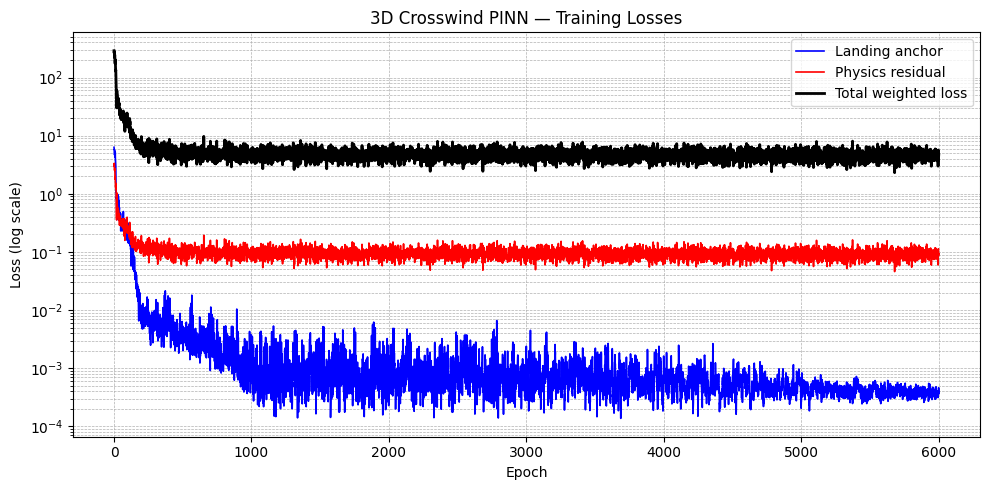

In [88]:
# ── Loss curves (log scale) ───────────────────────────────────────────────────

ep = np.arange(num_epochs)

plt.figure(figsize=(10, 5))

plt.plot(
    ep, hist['bc'],
    label='Landing anchor',
    color='blue', lw=1.2
)

plt.plot(
    ep, hist['ph'],
    label='Physics residual',
    color='red', lw=1.2
)

plt.plot(
    ep, hist['total'],
    label='Total weighted loss',
    color='black', lw=2.0
)

plt.yscale('log')

plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')

plt.title('3D Crosswind PINN — Training Losses')

plt.legend()
plt.grid(True, which='both', ls='--', lw=0.5)

plt.tight_layout()
plt.show()

## Validation — does the surrogate match RK4, and did it infer the right impact time?
The honest test of a forward PINN is to pick flights it never saw, run the trusted RK4 integrator,
and overlay. I report four numbers per flight: the **whole-trajectory RMSE** in each coordinate
(the fair, full-path error, not just the endpoint), the **downrange range** error, the
**crossrange drift** error (the point of this notebook), and the **inferred flight time** $T_f$
against RK4's. I include the previously-hard flight 3 (low angle, high drag, opposing winds) on
purpose — it is the one the two-stage training was meant to fix.


 flight   RMSE_x   RMSE_y   RMSE_z  RMSE_3D  range e  cross e    Tf e
      1     1.93     0.23     3.53     4.03     3.57     7.35   0.107
      2     8.86     1.48     1.38     9.09    16.53     3.08   0.169
      3     5.62     1.08     2.66     6.31    10.41     5.34   0.312

mean whole-trajectory RMSE over the 3 flights: 6.48 m


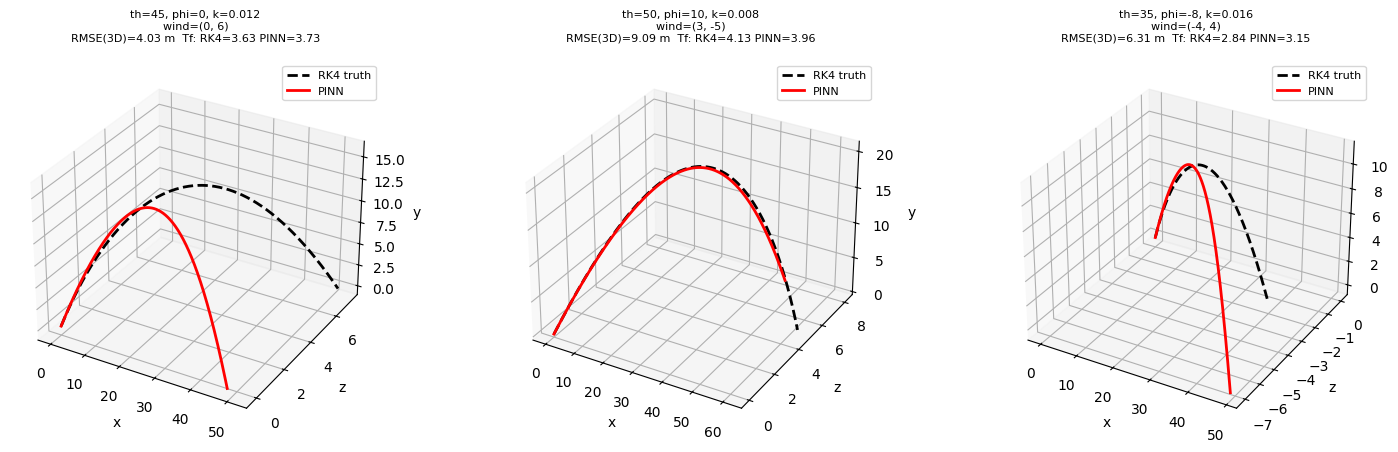

In [89]:
# ── Validate on unseen flights, and report whole-trajectory RMSE ──────────────
traj.eval(); tnet.eval()
test_flights = [
    (45,   0,   0.012,   0,   6),      # pure crosswind
    (50,  10,   0.008,   3,  -5),      # aim + wind mixed
    (35,  -8,   0.016,  -4,   4),      # low, draggy, opposing winds (the hard one)
]
fig = plt.figure(figsize=(15, 4.5))
rmse_all = []
print(f"{'flight':>7}{'RMSE_x':>9}{'RMSE_y':>9}{'RMSE_z':>9}{'RMSE_3D':>9}"
      f"{'range e':>9}{'cross e':>9}{'Tf e':>8}")

for i, (th, ph, k, wx, wz) in enumerate(test_flights):
    T, S = integrate3d(u_fixed, th, ph, k, (wx, 0, wz))  # RK4 truth
    with torch.no_grad():
        th_tensor = torch.tensor([[th]], dtype=torch.float32, device=device)
        Tf = tnet(cfeat(th, ph, k, wx, wz, 1), th_tensor).item()

        xi = torch.linspace(0, 1, len(T), device=device).unsqueeze(1)
        N  = traj(torch.cat([xi, cfeat(th, ph, k, wx, wz, len(T))], dim=1))
        thr, phr = np.radians(th), np.radians(ph)
        vx0 = u_fixed * np.cos(thr) * np.cos(phr)
        vy0 = u_fixed * np.sin(thr)
        vz0 = u_fixed * np.cos(thr) * np.sin(phr)

        xi_np = xi[:, 0].cpu().numpy()
        N_np = N.cpu().numpy()
        xi2_np = xi_np ** 2

        xp = vx0 * (xi_np * Tf) + xi2_np * N_np[:, 0] * x_ref
        yp = vy0 * (xi_np * Tf) + xi2_np * N_np[:, 1] * y_ref
        zp = vz0 * (xi_np * Tf) + xi2_np * N_np[:, 2] * z_ref
    # Whole-trajectory RMSE
    rmse_x  = np.sqrt(np.mean((xp - S[:, 0]) ** 2))
    rmse_y  = np.sqrt(np.mean((yp - S[:, 1]) ** 2))
    rmse_z  = np.sqrt(np.mean((zp - S[:, 2]) ** 2))
    rmse_3d = np.sqrt(np.mean((xp - S[:, 0]) ** 2 + (yp - S[:, 1]) ** 2 + (zp - S[:, 2]) ** 2))

    rng_err   = abs(xp[-1] - S[-1, 0])
    cross_err = abs(zp[-1] - S[-1, 2])
    tf_err    = abs(Tf - T[-1])
    rmse_all.append(rmse_3d)

    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.plot(S[:, 0], S[:, 2], S[:, 1], 'k--', lw=2, label='RK4 truth')
    ax.plot(xp, zp, yp, 'r-', lw=2, label='PINN')
    ax.set_xlabel('x')
    ax.set_ylabel('z')
    ax.set_zlabel('y')
    ax.set_title(f"th={th}, phi={ph}, k={k}\nwind=({wx}, {wz})\n"
                 f"RMSE(3D)={rmse_3d:.2f} m  Tf: RK4={T[-1]:.2f} PINN={Tf:.2f}\n",
                 fontsize=8)
    ax.legend(fontsize=8)
    print(f"{i+1:>7}{rmse_x:>9.2f}{rmse_y:>9.2f}{rmse_z:>9.2f}{rmse_3d:>9.2f}"
          f"{rng_err:>9.2f}{cross_err:>9.2f}{tf_err:>8.3f}")

print(f"\nmean whole-trajectory RMSE over the 3 flights: {np.mean(rmse_all):.2f} m")
plt.tight_layout()
plt.show()

## A small sensitivity map: azimuth vs crosswind
A single accuracy number hides the truth, so — as in Notebook 3 — I sweep a plane. Here the two
most interesting axes are **azimuth $\phi$** and **crosswind $w_z$**, because together they
control the crossrange landing. I record the crossrange-impact error (in metres) against RK4
across the plane. I expect low error inside the training box and growth outside it (PINNs
extrapolate poorly, since physics was only enforced inside).

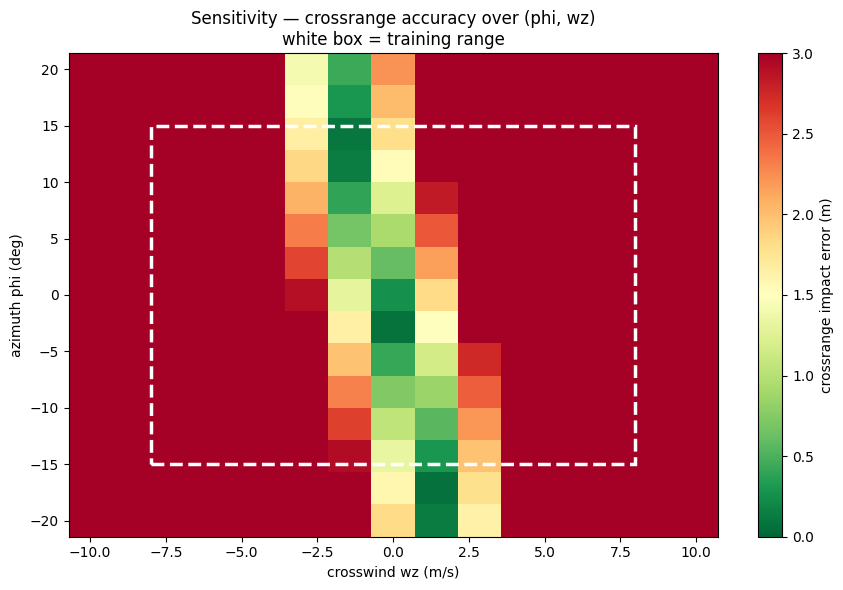

mean crossrange error inside grid: 6.22 m


In [90]:
# ── Sensitivity: crossrange impact error over (phi, wz) ───────────────────────
n_ph, n_wz = 15, 15
phi_sweep = np.linspace(phi_min - 5, phi_max + 5, n_ph)
wz_sweep  = np.linspace(w_min - 2,   w_max + 2,   n_wz)
err_grid  = np.full((n_ph, n_wz), np.nan)

traj.eval(); tnet.eval()
th_val = 45.0
th_tensor = torch.tensor([[th_val]], dtype=torch.float32, device=device)

with torch.no_grad():
    for a, ph in enumerate(phi_sweep):
        for b, wz in enumerate(wz_sweep):
            T, S = integrate3d(u_fixed, th_val, ph, 0.01, (0, 0, wz))
            Tf   = tnet(cfeat(th_val, ph, 0.01, 0, wz, 1), th_tensor).item()
            xi1  = torch.ones(1, 1, device=device)
            phr  = np.radians(ph)
            vz0  = u_fixed * np.cos(np.radians(th_val)) * np.sin(phr)

            # z(xi=1) = vz0 * Tf + (1.0)^2 * Nz * z_ref
            N1   = traj(torch.cat([xi1, cfeat(th_val, ph, 0.01, 0, wz, 1)], dim=1))
            z1   = vz0 * Tf + N1[0, 2].item() * z_ref
            err_grid[a, b] = abs(z1 - S[-1, 2])

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.pcolormesh(wz_sweep, phi_sweep, err_grid, cmap=plt.cm.RdYlGn_r,
                   vmin=0, vmax=3, shading='auto')
plt.colorbar(im, ax=ax, label='crossrange impact error (m)')
rect = plt.Rectangle((w_min, phi_min), w_max - w_min, phi_max - phi_min,
                     lw=2.5, edgecolor='white', facecolor='none', ls='--')
ax.add_patch(rect)
ax.set_xlabel('crosswind wz (m/s)')
ax.set_ylabel('azimuth phi (deg)')
ax.set_title('Sensitivity — crossrange accuracy over (phi, wz)\nwhite box = training range')
plt.tight_layout()
plt.show()

print(f"mean crossrange error inside grid: {np.nanmean(err_grid):.2f} m")

## What this notebook gives me
I now have a **fast, differentiable, 3-D crosswind surrogate** that generalises over two launch
angles, a drag coefficient, and a two-component wind — and that **infers its own impact time**
with a small companion network, no lookup table required. That surrogate is the fast forward
map I lean on in the inverse and targeting work. Everything here is **deterministic**: one set
of inputs gives exactly one trajectory. Real air is not deterministic, and that is the subject
of the next notebook.